In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Trần Công Nhân - 6451071054")

# Đọc dữ liệu Breast Cancer có sẵn từ sklearn
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Nếu đề dùng file CSV tải lên Colab (ví dụ 'data.csv' hoặc 'heart.csv'), mở comment dòng dưới:
# df = pd.read_csv('data.csv')

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Trần Công Nhân - 6451071054
Kích thước dữ liệu: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [2]:
print("Trần Công Nhân - 6451071054")

print("Thông tin dữ liệu:")
df.info()

print("\nSố lượng giá trị thiếu (Missing values) ở từng cột:")
print(df.isnull().sum())

print("\nSố dòng bị trùng lặp:", df.duplicated().sum())
df = df.drop_duplicates()
print("Kích thước dữ liệu sau khi làm sạch:", df.shape)

Trần Công Nhân - 6451071054
Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-

Trần Công Nhân - 6451071054


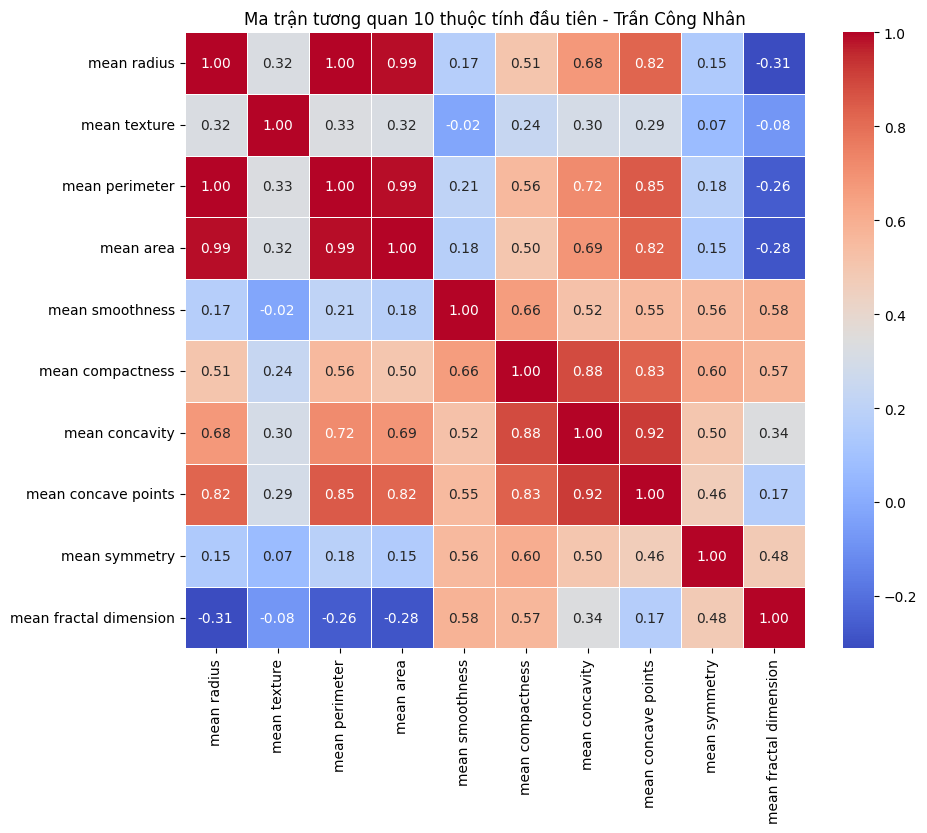

In [3]:
print("Trần Công Nhân - 6451071054")

# Vẽ ma trận tương quan 10 đặc trưng đầu tiên (mean features) để dễ quan sát
plt.figure(figsize=(10, 8))
corr = df.iloc[:, :10].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Ma trận tương quan 10 thuộc tính đầu tiên - Trần Công Nhân")
plt.show()

In [4]:
print("Trần Công Nhân - 6451071054")

X = df.drop('target', axis=1)
y = df['target']

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("\nPhân bố các nhãn trong y (0: Ác tính - Malignant, 1: Lành tính - Benign):")
print(y.value_counts())

Trần Công Nhân - 6451071054
Kích thước X: (569, 30)
Kích thước y: (569,)

Phân bố các nhãn trong y (0: Ác tính - Malignant, 1: Lành tính - Benign):
target
1    357
0    212
Name: count, dtype: int64


In [5]:
print("Trần Công Nhân - 6451071054")

categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print("Các cột dạng phi số trong X:", categorical_cols)

if len(categorical_cols) == 0:
    print("Tất cả thuộc tính điều kiện đều đã ở dạng số, sẵn sàng đưa vào mô hình.")
else:
    X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

Trần Công Nhân - 6451071054
Các cột dạng phi số trong X: []
Tất cả thuộc tính điều kiện đều đã ở dạng số, sẵn sàng đưa vào mô hình.


In [6]:
print("Trần Công Nhân - 6451071054")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

Trần Công Nhân - 6451071054
Kích thước X_train: (398, 30)
Kích thước X_test: (171, 30)
Kích thước y_train: (398,)
Kích thước y_test: (171,)


Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) mô hình ID3: 0.9649

Báo cáo phân lớp - ID3:
              precision    recall  f1-score   support

           0       0.97      0.94      0.95        63
           1       0.96      0.98      0.97       108

    accuracy                           0.96       171
   macro avg       0.97      0.96      0.96       171
weighted avg       0.96      0.96      0.96       171



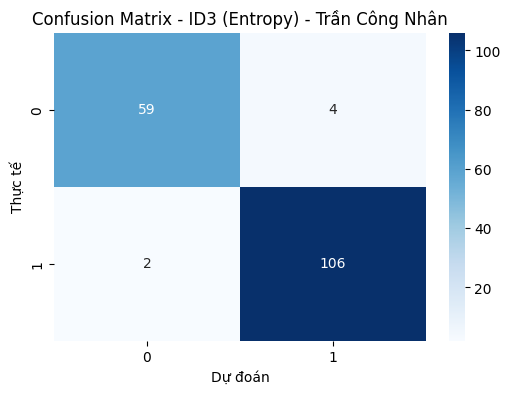

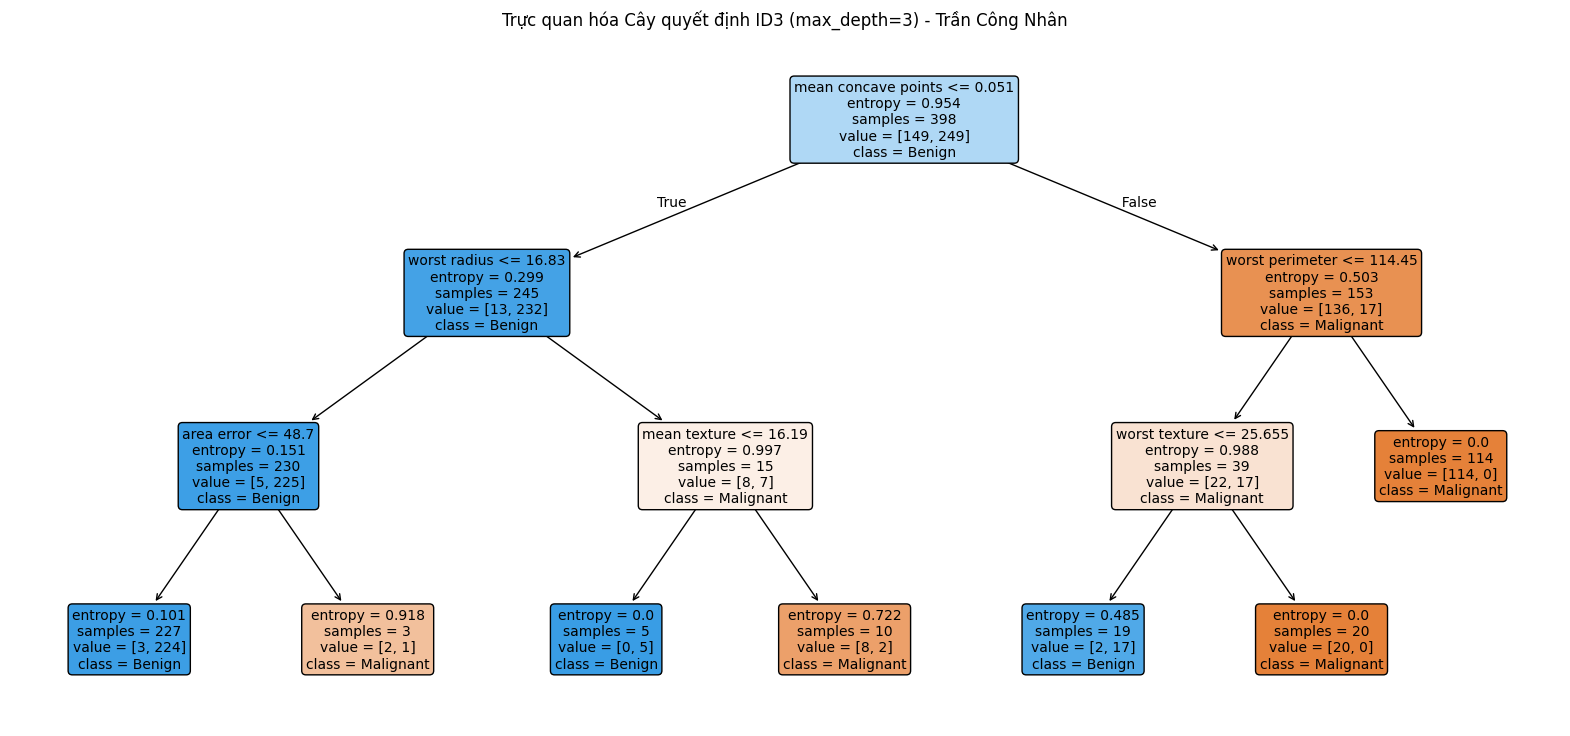

In [7]:
print("Trần Công Nhân - 6451071054")

id3_model = DecisionTreeClassifier(criterion='entropy', random_state=42)
id3_model.fit(X_train, y_train)

y_pred_id3 = id3_model.predict(X_test)
acc_id3 = accuracy_score(y_test, y_pred_id3)

print(f"Độ chính xác (Accuracy) mô hình ID3: {acc_id3:.4f}")
print("\nBáo cáo phân lớp - ID3:")
print(classification_report(y_test, y_pred_id3))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_id3), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - ID3 (Entropy) - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

# Trực quan hóa cây quyết định ID3 (giới hạn max_depth=3)
id3_vis = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
id3_vis.fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(id3_vis, feature_names=X_train.columns, class_names=['Malignant', 'Benign'], filled=True, rounded=True, fontsize=10)
plt.title("Trực quan hóa Cây quyết định ID3 (max_depth=3) - Trần Công Nhân")
plt.show()

Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) mô hình CART: 0.9415

Báo cáo phân lớp - CART:
              precision    recall  f1-score   support

           0       0.90      0.95      0.92        63
           1       0.97      0.94      0.95       108

    accuracy                           0.94       171
   macro avg       0.93      0.94      0.94       171
weighted avg       0.94      0.94      0.94       171



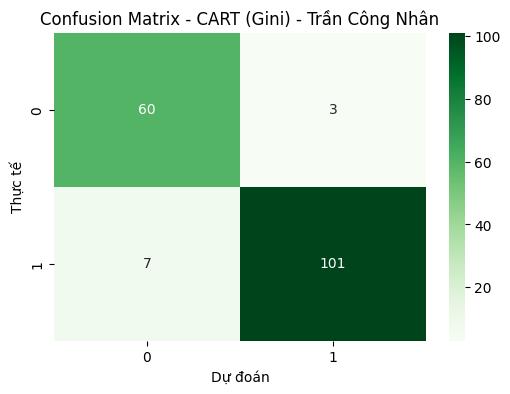

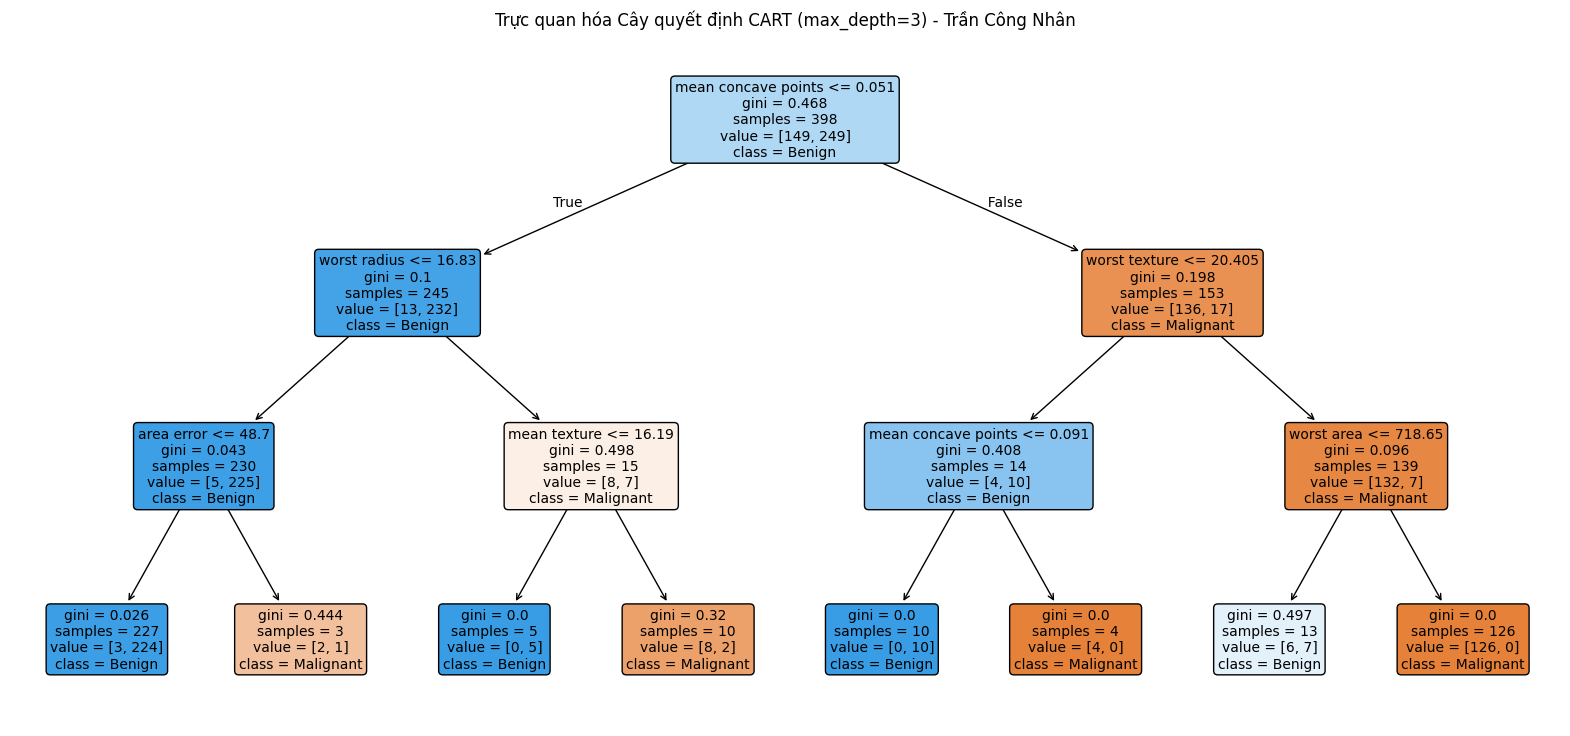

In [8]:
print("Trần Công Nhân - 6451071054")

cart_model = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_model.fit(X_train, y_train)

y_pred_cart = cart_model.predict(X_test)
acc_cart = accuracy_score(y_test, y_pred_cart)

print(f"Độ chính xác (Accuracy) mô hình CART: {acc_cart:.4f}")
print("\nBáo cáo phân lớp - CART:")
print(classification_report(y_test, y_pred_cart))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_cart), annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - CART (Gini) - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

# Trực quan hóa cây quyết định CART (giới hạn max_depth=3)
cart_vis = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
cart_vis.fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(cart_vis, feature_names=X_train.columns, class_names=['Malignant', 'Benign'], filled=True, rounded=True, fontsize=10)
plt.title("Trực quan hóa Cây quyết định CART (max_depth=3) - Trần Công Nhân")
plt.show()

Trần Công Nhân - 6451071054
Độ chính xác (Accuracy) mô hình Naive Bayes: 0.9415

Báo cáo phân lớp - Naive Bayes:
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        63
           1       0.95      0.96      0.95       108

    accuracy                           0.94       171
   macro avg       0.94      0.93      0.94       171
weighted avg       0.94      0.94      0.94       171



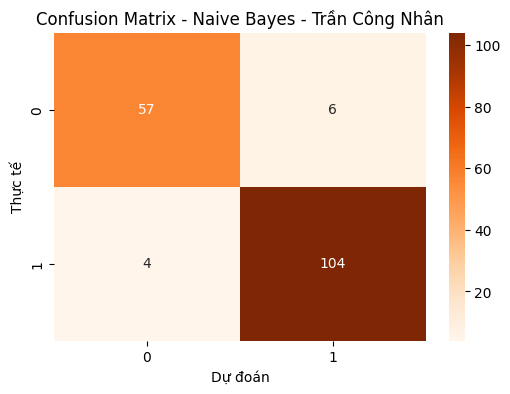

In [9]:
print("Trần Công Nhân - 6451071054")

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)
acc_nb = accuracy_score(y_test, y_pred_nb)

print(f"Độ chính xác (Accuracy) mô hình Naive Bayes: {acc_nb:.4f}")
print("\nBáo cáo phân lớp - Naive Bayes:")
print(classification_report(y_test, y_pred_nb))

# Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Naive Bayes - Trần Công Nhân")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

Trần Công Nhân - 6451071054


,Mô hình,Accuracy
0,ID3 (Entropy),0.964912
1,CART (Gini),0.941520
2,Naive Bayes,0.941520


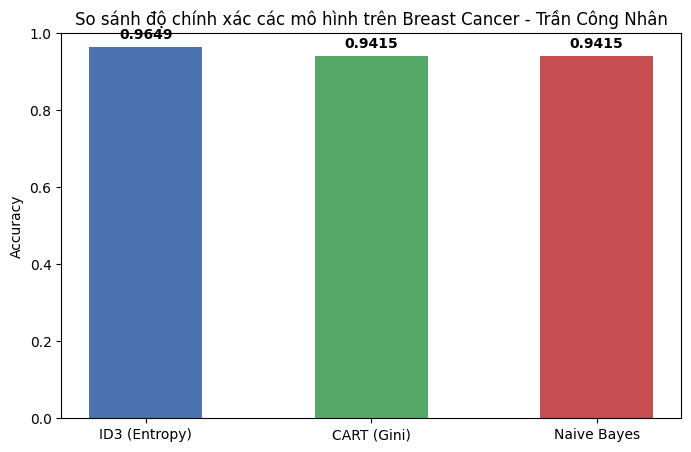

In [10]:
print("Trần Công Nhân - 6451071054")

model_names = ['ID3 (Entropy)', 'CART (Gini)', 'Naive Bayes']
accuracies = [acc_id3, acc_cart, acc_nb]

df_results = pd.DataFrame({'Mô hình': model_names, 'Accuracy': accuracies})
display(df_results)

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies, color=['#4C72B0', '#55A868', '#C44E52'], width=0.5)
plt.ylim(0, 1.0)
plt.ylabel('Accuracy')
plt.title('So sánh độ chính xác các mô hình trên Breast Cancer - Trần Công Nhân')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.02, f'{height:.4f}', ha='center', fontweight='bold')

plt.show()